# Titanic Survival Analysis: Data Wrangling & Exploratory Data Analysis (EDA)

**Objective:** Clean, validate, and analyze the Titanic passenger dataset (`n = 891`) to uncover key socio-economic and demographic factors influencing survival rates.

**Tools Used:** Python, Pandas, NumPy, Matplotlib

In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Load Dataset
df = pd.read_csv('titanic.csv')
display(df.head(3))
print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns\n")

# 2. Missing Values Audit Table
missing_count = df.isna().sum()
missing_percent = (missing_count / len(df) * 100).round(2)
audit_df = pd.DataFrame({'Missing': missing_count, 'Percent': missing_percent})
audit_df = audit_df[audit_df['Missing'] > 0].sort_values(by='Missing', ascending=False)

print("--- Missing Values Audit ---")
display(audit_df)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S


Dataset Shape: 891 rows, 12 columns

--- Missing Values Audit ---


,Missing,Percent
Cabin,687,77.10
Age,177,19.87
Embarked,2,0.22


## 1. Data Cleaning & Validation
To preserve data integrity without distorting distributions:
* **Age:** Imputed missing values (19.87%) using the **median** to avoid skewing from extreme outliers.
* **Embarked:** Imputed missing values (0.22%) using the **mode**.
* **Cabin:** Dropped the column due to excessive missingness (>77%).

In [21]:
clean_df = df.copy()

# Imputation & Dropping
clean_df['Age'] = clean_df['Age'].fillna(clean_df['Age'].median())
clean_df['Embarked'] = clean_df['Embarked'].fillna(clean_df['Embarked'].mode()[0])
clean_df = clean_df.drop(columns=['Cabin'])

# Data Type Optimization
clean_df['Pclass'] = clean_df['Pclass'].astype('category')
clean_df['Embarked'] = clean_df['Embarked'].astype('category')

# Data Integrity Assertions
assert len(clean_df) == len(df), "Row count mismatch!"
assert clean_df.isna().sum().sum() == 0, "Missing values still exist!"
assert clean_df['PassengerId'].is_unique, "Duplicate PassengerIDs found!"
assert clean_df['Survived'].isin([0, 1]).all(), "Invalid Survived values!"
assert clean_df['Age'].between(0, 100).all(), "Age out of expected range!"

print(f"Data cleaned & validated successfully! New shape: {clean_df.shape}")

Data cleaned & validated successfully! New shape: (891, 11)


## 2. Feature Engineering & Survival Analysis
Created behavioral and socio-economic features (`FamilySize`, `IsAlone`, and `HighFare`) to evaluate survival patterns across different passenger segments.

In [22]:
# Feature Engineering
clean_df['FamilySize'] = clean_df['SibSp'] + clean_df['Parch'] + 1
clean_df['IsAlone'] = (clean_df['FamilySize'] == 1).astype(int)
clean_df['HighFare'] = clean_df['Fare'] > clean_df['Fare'].median()

# Overall Survival Rate
overall_rate = clean_df['Survived'].mean() * 100
print(f"Overall Survival Rate: {overall_rate:.2f}%\n")

# Grouped Summaries
for col in ['Pclass', 'IsAlone', 'HighFare']:
    summary = clean_df.groupby(col, observed=False)['Survived'].agg(
        Passengers='count',
        Survivors='sum',
        Survival_Rate=lambda x: (x.mean() * 100).round(2)
    )
    print(f"--- Survival by {col} ---")
    display(summary)

Overall Survival Rate: 38.38%

--- Survival by Pclass ---


,Passengers,Survivors,Survival_Rate
Pclass,,,
1,216,136,62.96
2,184,87,47.28
3,491,119,24.24


--- Survival by IsAlone ---


,Passengers,Survivors,Survival_Rate
IsAlone,,,
0,354,179,50.56
1,537,163,30.35


--- Survival by HighFare ---


,Passengers,Survivors,Survival_Rate
HighFare,,,
False,447,112,25.06
True,444,230,51.80


## 3. Data Visualization & Export
Visualizing survival rates across passenger class, family travel status, and fare tiers to highlight key disparities.

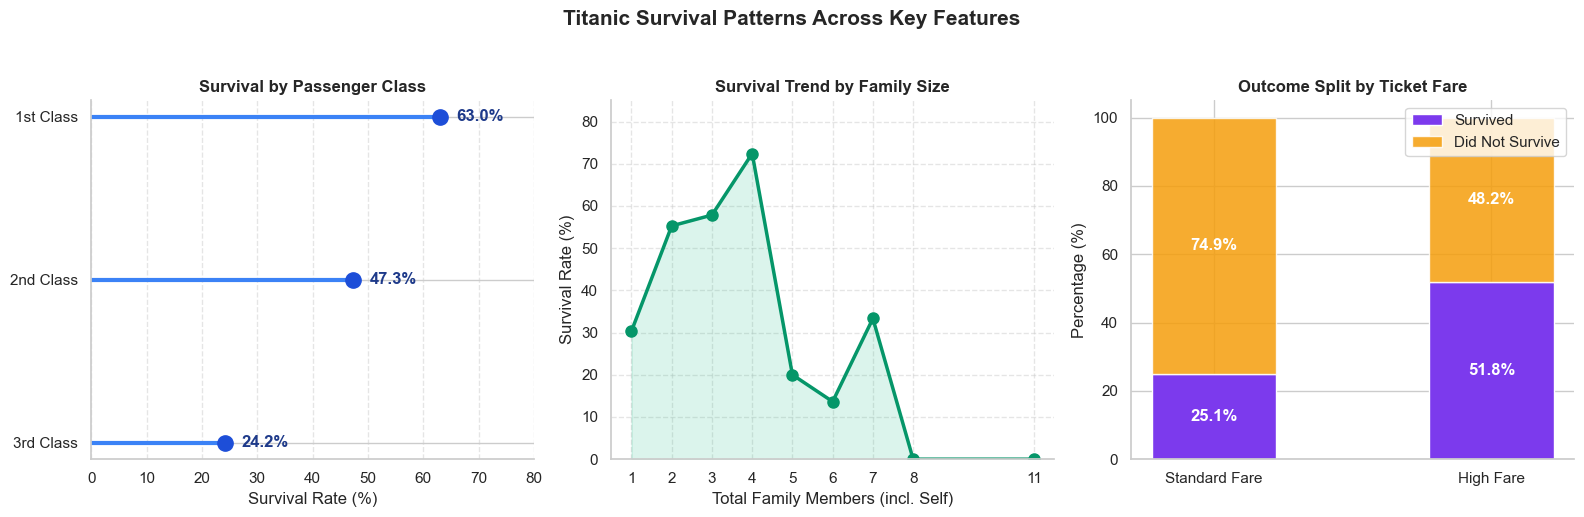

Exported 'titanic_cleaned.csv' successfully!


In [23]:

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.patch.set_facecolor('white')

# 1. Pclass -> Lollipop Chart (Blue theme)
pclass_rates = clean_df.groupby('Pclass', observed=False)['Survived'].mean() * 100
classes = ['1st Class', '2nd Class', '3rd Class']
axes[0].hlines(y=classes, xmin=0, xmax=pclass_rates.values, color='#3b82f6', linewidth=3)
axes[0].plot(pclass_rates.values, classes, 'o', markersize=11, color='#1d4ed8')
axes[0].set_title('Survival by Passenger Class', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Survival Rate (%)')
axes[0].set_xlim(0, 80)
axes[0].invert_yaxis()
axes[0].grid(axis='x', linestyle='--', alpha=0.5)
for i, v in enumerate(pclass_rates.values):
    axes[0].text(v + 3, i, f'{v:.1f}%', va='center', fontweight='bold', color='#1e3a8a')

# 2. FamilySize -> Line Plot (Emerald Green theme)
fam_rates = clean_df.groupby('FamilySize')['Survived'].mean() * 100
axes[1].plot(fam_rates.index, fam_rates.values, marker='o', linewidth=2.5, markersize=8, color='#059669')
axes[1].fill_between(fam_rates.index, fam_rates.values, color='#10b981', alpha=0.15)
axes[1].set_title('Survival Trend by Family Size', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Total Family Members (incl. Self)')
axes[1].set_ylabel('Survival Rate (%)')
axes[1].set_xticks(fam_rates.index)
axes[1].set_ylim(0, 85)
axes[1].grid(True, linestyle='--', alpha=0.5)

# 3. HighFare -> 100% Stacked Bar (Purple & Amber theme)
fare_ct = pd.crosstab(clean_df['HighFare'], clean_df['Survived'], normalize='index') * 100
fare_labels = ['Standard Fare', 'High Fare']
axes[2].bar(fare_labels, fare_ct[1], label='Survived', color='#7c3aed', width=0.45)
axes[2].bar(fare_labels, fare_ct[0], bottom=fare_ct[1], label='Did Not Survive', color='#f59e0b', alpha=0.85, width=0.45)
axes[2].set_title('Outcome Split by Ticket Fare', fontsize=12, fontweight='bold')
axes[2].set_ylabel('Percentage (%)')
axes[2].legend(loc='upper right', frameon=True)
for i in range(len(fare_labels)):
    s_val = fare_ct[1].iloc[i]
    d_val = fare_ct[0].iloc[i]
    axes[2].text(i, s_val / 2, f'{s_val:.1f}%', ha='center', va='center', color='white', fontweight='bold')
    axes[2].text(i, s_val + d_val / 2, f'{d_val:.1f}%', ha='center', va='center', color='white', fontweight='bold')

for ax in axes:
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

plt.suptitle('Titanic Survival Patterns Across Key Features', fontsize=15, fontweight='bold', y=1.03)
plt.tight_layout()
plt.savefig('titanic_custom_charts.png', dpi=300, bbox_inches='tight')
plt.show()

clean_df.to_csv('titanic_cleaned.csv', index=False)
print("Exported 'titanic_cleaned.csv' successfully!")

## 4. Key Insights & Limitations

### Key Findings
* **Overall Survival:** Only **38.38%** of the 891 passengers survived.
* **Ticket Class (`Pclass`):** 1st-class passengers had the highest survival rate (**62.96%**), compared to **47.28%** in 2nd class and **24.24%** in 3rd class.
* **Ticket Fare (`HighFare`):** Passengers who paid above the median fare were more than twice as likely to survive (**51.80%** vs. **25.06%**).
* **Family Presence (`IsAlone`):** Passengers traveling with family had a much higher survival rate (**50.56%**) than solo travelers (**30.35%**).

### Data Cleaning Impact
* Dropping the `Cabin` column (>77% missing) prevented unreliable assumptions.
* Filling missing `Age` values with the median preserved all 891 records without skewing the data with extreme ages.

### Limitation (Association ≠ Causation)
* Paying a higher fare or holding a 1st-class ticket did not directly cause survival; instead, these factors reflected closer cabin access to the upper deck and lifeboats during evacuation.